<a href="https://colab.research.google.com/github/wjd123p/IT326-Project/blob/main/Reports/Phase3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Phase 3: Data Mining**




## [1] Problem

## [2] Data Mining Task

## [3] Data

## [4] Data preprocessing

## [5] Data Mining Technique

## [5] Modeling & Evaluation (Unsupervised Learning: K-Means Clustering)

### Tools & Libraries Description
To perform unsupervised clustering and identify natural groupings within the student dataset, the following Python libraries and functions were utilized:
* **`StandardScaler` (from `sklearn.preprocessing`):** Used to standardize numerical features to have a mean of 0 and a variance of 1, ensuring all variables contribute equally to the distance calculations.
* **`KMeans` (from `sklearn.cluster`):** The core algorithm used to partition the dataset into $k$ distinct clusters by minimizing within-cluster variances.
* **`silhouette_score` (from `sklearn.metrics`):** Evaluates cluster cohesion and separation, yielding scores between -1 and 1.
* **`Matplotlib` & `Seaborn`:** Utilized to plot the Elbow curve, Silhouette analysis, and the final cluster scatter plots.
* **`calinski_harabasz_score` (from `sklearn.metrics`):** Measures the ratio of between-cluster to within-cluster variance.
* **`KneeLocator` (from `kneed`):** Detects the elbow point automatically.
* The class label `final_grade` was removed before clustering.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score

df = pd.read_csv("Preprocessed_dataset.csv")
label_col = "final_grade"
features = df.drop(label_col, axis=1)

scaled_features = StandardScaler().fit_transform(features)
data_scaled = pd.DataFrame(scaled_features, columns=features.columns)
print(data_scaled.head())

     gender  study_time_hours  attendance_percent  sleep_hours  \
0  1.026781          0.304615            1.409536    -0.257959   
1 -0.973917          1.886541            1.630906    -0.928807   
2  1.026781          0.923629            0.003836     0.916024   
3  1.026781         -0.658297           -0.859508     0.999880   
4  1.026781         -0.933415            0.479782    -1.851223   

   parental_education  internet_access  extracurricular_activities  \
0            0.192338         0.412354                    0.862949   
1           -0.914447         0.412354                    0.862949   
2            0.192338         0.412354                   -1.158817   
3           -0.914447         0.412354                    0.862949   
4            0.192338         0.412354                   -1.158817   

   part_time_job  previous_grade  final_exam_score  
0      -0.681385        0.563863          1.607952  
1       1.467599        0.451798          1.607952  
2       1.467599       

Elbow at k = 5


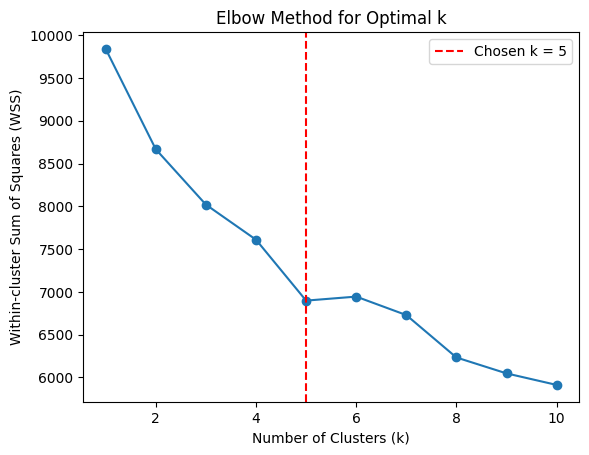

In [ ]:
%pip install Kneed
from kneed import KneeLocator

wss_values = []
k_values = range(1, 11)
for k in k_values:
    km = KMeans(n_clusters=k, random_state=42).fit(data_scaled)
    wss_values.append(km.inertia_)

knee = KneeLocator(list(k_values), wss_values, curve="convex", direction="decreasing")
print("Elbow at k =", knee.elbow)

plt.plot(k_values, wss_values, marker="o")
if knee.elbow is not None:
    plt.axvline(x=knee.elbow, linestyle="--", color="red", label=f"Chosen k = {knee.elbow}")
    plt.legend()
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Within-cluster Sum of Squares (WSS)")
plt.title("Elbow Method for Optimal k")
plt.show()

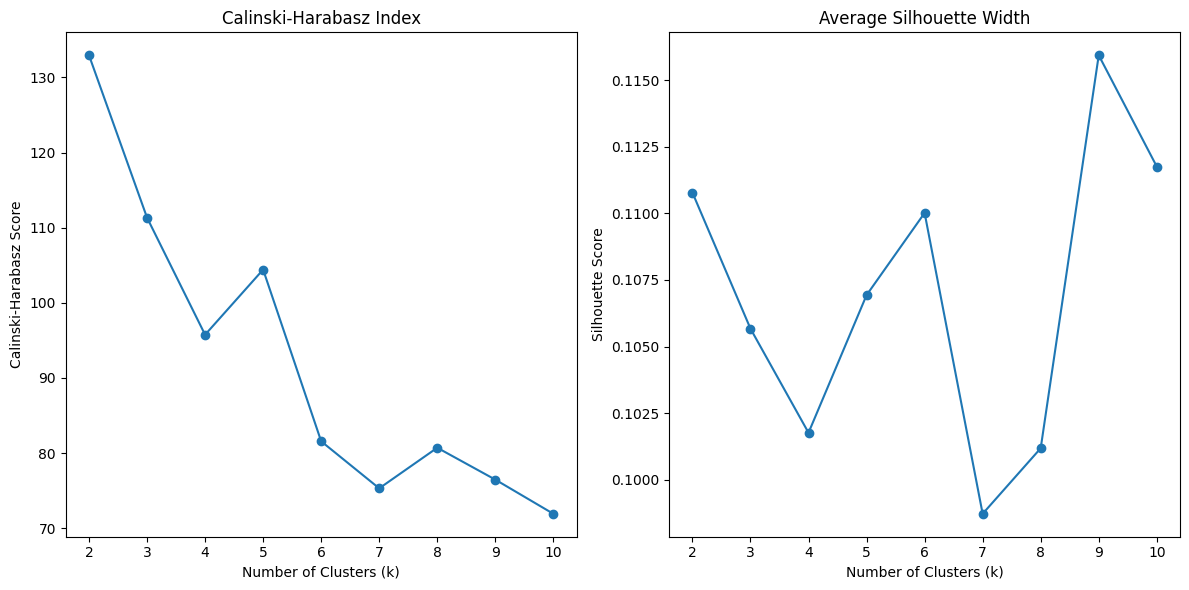

Best K by Silhouette: 9
Best K by Calinski-Harabasz: 2


In [ ]:
k_range = range(2, 11)
ch_scores, silhouette_scores = [], []
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42).fit(data_scaled)
    ch_scores.append(calinski_harabasz_score(data_scaled, km.labels_))
    silhouette_scores.append(silhouette_score(data_scaled, km.labels_))

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(k_range, ch_scores, marker="o")
plt.title("Calinski-Harabasz Index")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Calinski-Harabasz Score")
plt.subplot(1, 2, 2)
plt.plot(k_range, silhouette_scores, marker="o")
plt.title("Average Silhouette Width")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.tight_layout()
plt.show()

best_sil = list(k_range)[silhouette_scores.index(max(silhouette_scores))]
best_ch = list(k_range)[ch_scores.index(max(ch_scores))]
print("Best K by Silhouette:", best_sil)
print("Best K by Calinski-Harabasz:", best_ch)

### Optimal K Choice & Justification
We tested K = 2 to 10 and selected K = 2, 3 and 4. K = 2 has the highest Calinski-Harabasz index (133.0) and a Silhouette of 0.111. The WSS decreases gradually without a sharp elbow, so we kept small K values for easier interpretation. All Silhouette values are low (about 0.10 to 0.12), which means the clusters overlap and the structure in the data is weak.

In [ ]:
ks = [2, 3, 4]
models = {}
for k in ks:
    models[k] = KMeans(n_clusters=k, random_state=42).fit(data_scaled)
    print(f"K={k} | Silhouette = {silhouette_score(data_scaled, models[k].labels_):.4f} | WSS = {models[k].inertia_:.2f}")

K=2 | Silhouette = 0.1108 | WSS = 8666.59
K=3 | Silhouette = 0.1057 | WSS = 8019.57
K=4 | Silhouette = 0.1018 | WSS = 7609.40


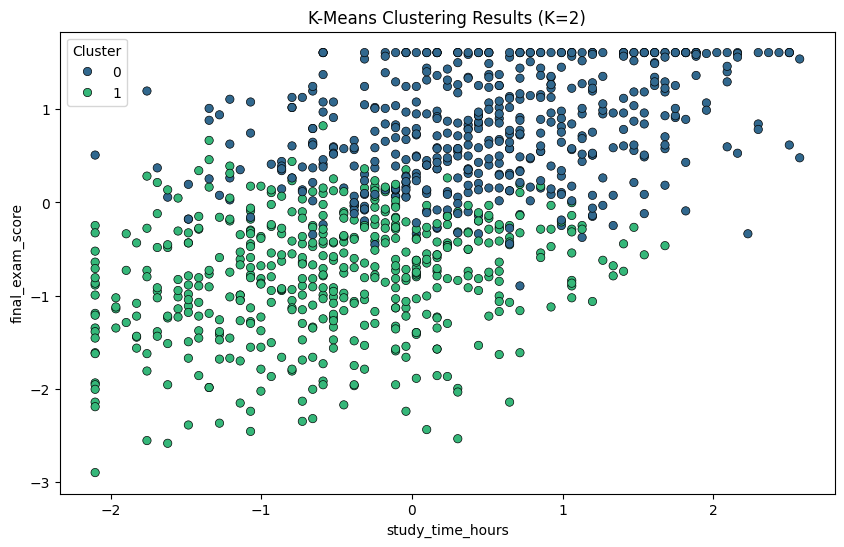

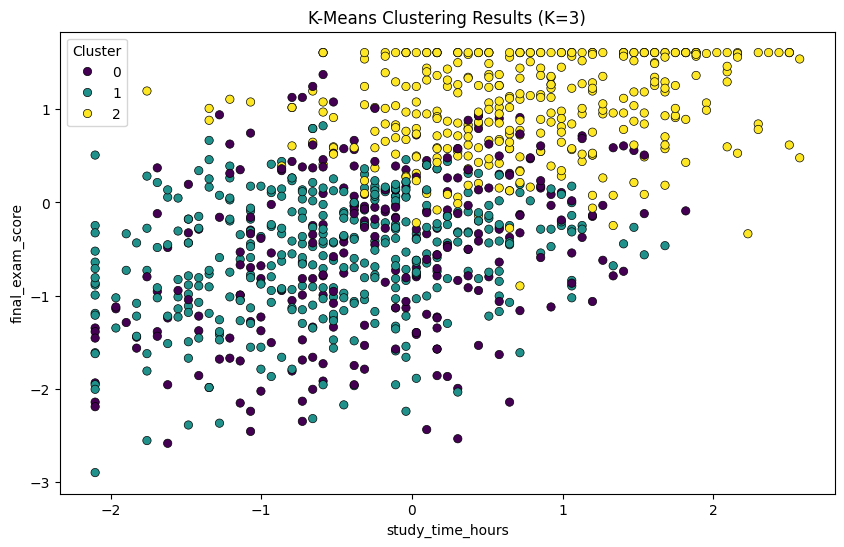

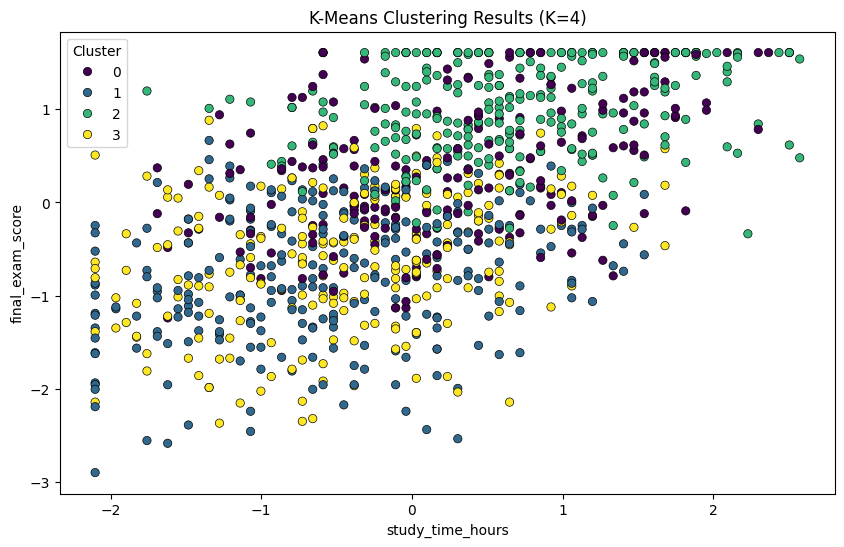

In [ ]:
for k in ks:
    plot_df = data_scaled.copy()
    plot_df["Cluster"] = models[k].labels_
    plt.figure(figsize=(10, 6))
    sns.scatterplot(x="study_time_hours", y="final_exam_score", hue="Cluster",
                    data=plot_df, palette="viridis", edgecolor="k")
    plt.title(f"K-Means Clustering Results (K={k})")
    plt.show()

In [ ]:
summary = pd.DataFrame({
    f"K={k}": {
        "Average Silhouette width": silhouette_score(data_scaled, models[k].labels_),
        "Total within-cluster SS": models[k].inertia_
    } for k in ks
})
print(summary)

                                  K=2          K=3          K=4
Average Silhouette width     0.110783     0.105672     0.101762
Total within-cluster SS   8666.586184  8019.571831  7609.404585


- K=2: Silhouette = 0.111, WSS = 8666.6. The clusters overlap but this K has the best Silhouette and Calinski-Harabasz among the three.
- K=3: Silhouette = 0.106, WSS = 8019.6. WSS drops but the Silhouette is lower, so separation is slightly worse.
- K=4: Silhouette = 0.102, WSS = 7609.4. WSS drops more but the Silhouette is the lowest, so the clusters overlap more.

Best K (majority rule): K = 2, supported by the highest Calinski-Harabasz and the highest Silhouette among the three chosen values.